# PDP-CR — Phase 1 Pilot: GA vs TSR vs MLS

**Dữ liệu:** Li–Lim (tọa độ pickup/delivery) chuyển đổi sang PDP-CR bằng quy tắc trong nghiên cứu của Thảo: `processing = Euclidean(pickup, delivery)`, `travel = Euclidean(delivery_i, pickup_j)`, `r_i ~ Uniform{1,...,5}`; `m=10`.

**Thí nghiệm:** 3 họ mặc định LC1, LR1, LRC1 × n=50,100,200 = **9 instance**, mỗi phương pháp 5 seed song song và cùng giới hạn thời gian. Có thể thêm LC2, LR2 để thành 15 instance. GA, TSR và MLS sử dụng **cùng mô hình và evaluator**. MLS chỉ dùng greedy randomized + bounded descent, không có population/crossover.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "pdpcr" / "genetic.py").is_file(), "Mở notebook từ thư mục project đã giải nén."

# ---- THAM SỐ CHỈNH TẠI ĐÂY ----
DEMO_MODE = False           # True: test offline 1 instance; False: pilot thật
SIZES = [50, 100, 200]
FAMILIES = ["LC1", "LR1", "LRC1"]   # Thêm "LC2", "LR2" để thành 15 instance
SEEDS = [0, 1, 2, 3, 4]
WORKERS = 5
GA_POPULATION = 16
SECONDS_BY_N = {50: 30.0, 100: 60.0, 200: 120.0}
RESULT_NAME = "pilot_9"  # chọn tên mới nếu thay đổi cấu hình/budget
PLOT_N = 100
PLOT_FAMILY = "LC1"
AUTO_DOWNLOAD = True

if DEMO_MODE:
    SIZES, FAMILIES = [50], ["LR2"]
    SECONDS_BY_N[50] = 2.0
    RESULT_NAME = "demo_offline"
    PLOT_N, PLOT_FAMILY = 50, "LR2"
print("Cases:", len(SIZES) * len(FAMILIES), "| Methods: GA, TSR, MLS | Seeds/method:", len(SEEDS))

Cases: 9 | Methods: GA, TSR, MLS | Seeds/method: 5


In [2]:
from prepare_instances import prepare, make_local_demo

if DEMO_MODE:
    _, demo_path = make_local_demo()
    manifest_path = ROOT / "instances" / "demo_manifest.json"
    demo_spec = {"name": demo_path.stem, "n": 50, "m": 10, "family": "LR2",
                 "source_id": "LR2_2_6 (first 50)", "requirement_seed": 0,
                 "instance_file": str(demo_path.relative_to(ROOT)),
                 "optimal_reference": None}
    manifest_path.write_text(json.dumps([demo_spec], indent=2), encoding="utf-8")
    print("Offline demo data:", demo_path)
else:
    prepared = prepare(sizes=SIZES, families=FAMILIES, robots=10,
                       requirement_seed=0, download=AUTO_DOWNLOAD)
    manifest_path = ROOT / "instances" / "manifest.json"
    print("Prepared", len(prepared), "independent converted instances")

Prepared lilim_lc101_n50_m10_req0_first50.json [LC1; 50/53 source tasks; first 50 complete requests ordered by original pickup ID]
Prepared lilim_lr101_n50_m10_req0_first50.json [LR1; 50/53 source tasks; first 50 complete requests ordered by original pickup ID]
Prepared lilim_lrc101_n50_m10_req0_first50.json [LRC1; 50/53 source tasks; first 50 complete requests ordered by original pickup ID]
Prepared lilim_lc1_2_1_n100_m10_req0_first100.json [LC1; 100/106 source tasks; first 100 complete requests ordered by original pickup ID]
Prepared lilim_lr1_2_1_n100_m10_req0_first100.json [LR1; 100/105 source tasks; first 100 complete requests ordered by original pickup ID]
Prepared lilim_lrc1_2_1_n100_m10_req0_first100.json [LRC1; 100/106 source tasks; first 100 complete requests ordered by original pickup ID]
Prepared lilim_lc1_4_1_n200_m10_req0_first200.json [LC1; 200/211 source tasks; first 200 complete requests ordered by original pickup ID]
Prepared lilim_lr1_4_1_n200_m10_req0_first200.json 

In [3]:
from run_pilot import run_pilot

OUTPUT = ROOT / "results" / RESULT_NAME
comparison = run_pilot(sizes=SIZES, families=FAMILIES,
                       seeds=SEEDS, seconds_by_n=SECONDS_BY_N,
                       workers=WORKERS, population=GA_POPULATION,
                       manifest=manifest_path, output_dir=OUTPUT, resume=True)
print("Saved to:", OUTPUT)

n=50 LC1 | GA: 5 seeds, 30.0s/seed, 5 workers
  seed 3: objective=381.7361; wall=30.00s cpu=24.02s
  seed 1: objective=357.9339; wall=30.00s cpu=24.27s
  seed 2: objective=361.2644; wall=30.00s cpu=24.41s
  seed 0: objective=371.5151; wall=30.01s cpu=24.44s
  seed 4: objective=354.8273; wall=30.01s cpu=24.31s
  finished in 30.47s total wall
n=50 LC1 | TSR: 5 seeds, 30.0s/seed, 5 workers
  seed 1: objective=409.8527; wall=30.00s cpu=20.05s
  seed 0: objective=400.3157; wall=30.01s cpu=20.03s
  seed 4: objective=407.8542; wall=30.00s cpu=19.84s
  seed 2: objective=403.6674; wall=30.01s cpu=19.92s
  seed 3: objective=400.6390; wall=30.00s cpu=18.91s
  finished in 30.56s total wall
n=50 LC1 | MLS: 5 seeds, 30.0s/seed, 5 workers
  seed 3: objective=383.1429; wall=30.00s cpu=22.31s
  seed 1: objective=363.0712; wall=30.00s cpu=22.77s
  seed 4: objective=386.4920; wall=30.00s cpu=22.67s
  seed 0: objective=353.7534; wall=30.00s cpu=22.03s
  seed 2: objective=374.9623; wall=30.00s cpu=22.06s
 

In [4]:
results = pd.read_csv(OUTPUT / "comparison.csv")
summary = pd.read_csv(OUTPUT / "summary.csv")
overall = pd.read_csv(OUTPUT / "overall.csv")
display(results.round(3))
display(overall.round(3))
print("GA vs TSR — positive improvement (%) means GA wins:")
if "GA_improvement_vs_TSR_pct" in results:
    print(results[["n", "family", "GA_improvement_vs_TSR_pct"]].round(3).to_string(index=False))

,instance,family,n,m,best_found,reference_type,GA_best_of_5,GA_mean,GA_best_RPD_pct,GA_best_seed,TSR_best_of_5,TSR_mean,TSR_best_RPD_pct,TSR_best_seed,MLS_best_of_5,MLS_mean,MLS_best_RPD_pct,MLS_best_seed,GA_improvement_vs_TSR_pct,GA_improvement_vs_MLS_pct
0,lilim_lc101_n50_m10_req0_first50,LC1,50,10,353.753,best_found_in_this_pilot_not_OPT,354.827,365.455,0.304,4,400.316,404.466,13.162,0,353.753,372.284,0.000,0,11.363,-0.304
1,lilim_lr101_n50_m10_req0_first50,LR1,50,10,536.078,best_found_in_this_pilot_not_OPT,536.078,538.894,0.000,3,547.263,550.354,2.087,0,545.393,560.863,1.738,1,2.044,1.708
2,lilim_lrc101_n50_m10_req0_first50,LRC1,50,10,580.074,best_found_in_this_pilot_not_OPT,580.074,582.162,0.000,4,605.573,614.477,4.396,4,624.916,635.606,7.730,2,4.211,7.176
3,lilim_lc1_2_1_n100_m10_req0_first100,LC1,100,10,819.222,best_found_in_this_pilot_not_OPT,820.659,828.917,0.175,1,819.222,833.484,0.000,1,829.998,842.572,1.315,3,-0.175,1.125
4,lilim_lr1_2_1_n100_m10_req0_first100,LR1,100,10,1870.745,best_found_in_this_pilot_not_OPT,1870.745,1872.631,0.000,3,1882.222,1884.382,0.613,1,1885.823,1885.823,0.806,0,0.610,0.800
5,lilim_lrc1_2_1_n100_m10_req0_first100,LRC1,100,10,1426.064,best_found_in_this_pilot_not_OPT,1426.064,1468.908,0.000,0,1457.359,1475.476,2.195,4,1478.994,1491.427,3.712,1,2.147,3.579
6,lilim_lc1_4_1_n200_m10_req0_first200,LC1,200,10,1758.316,best_found_in_this_pilot_not_OPT,1758.316,1797.614,0.000,3,1787.885,1792.142,1.682,4,1785.290,1815.905,1.534,3,1.654,1.511
7,lilim_lr1_4_1_n200_m10_req0_first200,LR1,200,10,3759.785,best_found_in_this_pilot_not_OPT,3760.040,3764.444,0.007,2,3759.785,3761.061,0.000,4,3857.549,3857.549,2.600,0,-0.007,2.528
8,lilim_lrc1_4_1_n200_m10_req0_first200,LRC1,200,10,2931.352,best_found_in_this_pilot_not_OPT,2942.340,3015.000,0.375,3,2931.352,2933.772,0.000,4,2986.400,3065.466,1.878,2,-0.375,1.475


,n,method,instance_count,avg_best_RPD_pct,avg_mean_RPD_pct,mean_cpu_total_seconds
0,50,GA,3,0.101,1.398,117.234
1,50,TSR,3,6.548,7.643,109.073
2,50,MLS,3,3.156,6.478,113.964
3,100,GA,3,0.058,1.430,216.578
4,100,TSR,3,0.936,1.978,225.932
5,100,MLS,3,1.944,2.747,238.984
6,200,GA,3,0.127,1.738,436.927
7,200,TSR,3,0.561,0.680,438.396
8,200,MLS,3,2.004,3.484,432.625


GA vs TSR — positive improvement (%) means GA wins:
  n family  GA_improvement_vs_TSR_pct
 50    LC1                     11.363
 50    LR1                      2.044
 50   LRC1                      4.211
100    LC1                     -0.175
100    LR1                      0.610
100   LRC1                      2.147
200    LC1                      1.654
200    LR1                     -0.007
200   LRC1                     -0.375


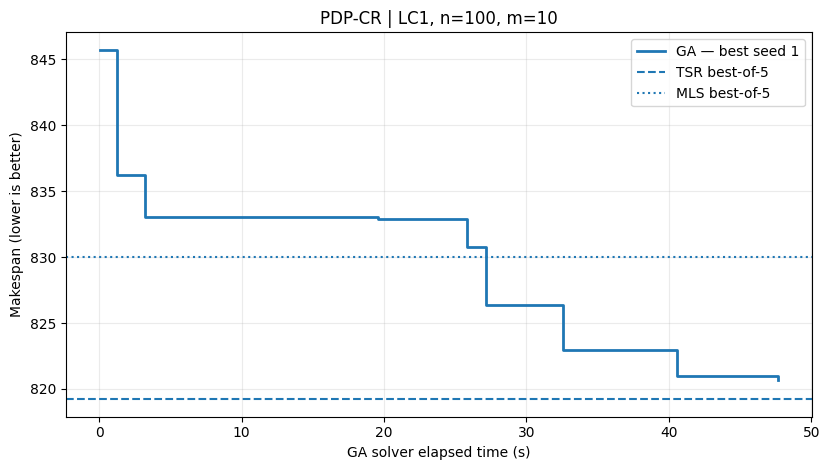

In [5]:
# Chỉ MỘT đường hội tụ: seed GA tốt nhất của instance được chọn.
selected = results[(results["n"] == PLOT_N) & (results["family"] == PLOT_FAMILY)]
if selected.empty:
    raise ValueError("PLOT_N / PLOT_FAMILY chưa nằm trong tập vừa chạy")
row = selected.iloc[0]
instance_name = row["instance"]
ga = json.loads((OUTPUT / "best" / f"{instance_name}__GA.json").read_text(encoding="utf8"))
x = [event["seconds"] for event in ga["history"]]
y = [event["best"] for event in ga["history"]]
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.step(x, y, where="post", label=f"GA — best seed {ga['seed']}", linewidth=2)
ax.axhline(float(row["TSR_best_of_5"]), linestyle="--", label="TSR best-of-5")
ax.axhline(float(row["MLS_best_of_5"]), linestyle=":", label="MLS best-of-5")
ax.set(title=f"PDP-CR | {PLOT_FAMILY}, n={PLOT_N}, m=10",
       xlabel="GA solver elapsed time (s)", ylabel="Makespan (lower is better)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / f"convergence_{PLOT_FAMILY}_n{PLOT_N}_GA_best.png", dpi=160)
plt.show()

### File đầu ra

- `results/<RESULT_NAME>/runs.csv`: từng seed, thời gian thực thi, objective và RPD.
- `results/<RESULT_NAME>/summary.csv`: best-of-5, mean, std của mỗi thuật toán trên từng instance.
- `results/<RESULT_NAME>/comparison.csv`: so sánh trực tiếp GA–TSR–MLS và best-found.
- `results/<RESULT_NAME>/overall.csv`: trung bình RPD theo quy mô.
- `results/<RESULT_NAME>/best/`: nghiệm, flow và lịch sử của seed tốt nhất.
- `results/<RESULT_NAME>/seeds/`: kết quả từng seed để có thể resume.

**Ghi chú khoa học:** Pilot này đánh giá khả năng cạnh tranh của GA; để viết journal vẫn cần bộ thí nghiệm lớn hơn, nhiều lần chạy độc lập và kiểm định thống kê. Với GA Best-of-5, không được nhầm best-found/RPD với optimality gap. Mỗi process có population 16 riêng; tổng CPU-seconds cũng được lưu để so sánh công bằng.

In [ ]:
# CPLEX: one run per instance vs saved GA best-of-5; no GA rerun.
from pathlib import Path
import hashlib
import json
import pandas as pd
from pdpcr.core import Instance, evaluate, replay_routes
from pdpcr.cplex_cli import (MODEL_VERSION, instance_fingerprint,
                             solve_cplex)

CPLEX_EXE = Path(r"C:\Program Files\IBM\ILOG\CPLEX_Studio2212\cplex\bin\x64_win64\cplex.exe")
CPLEX_SEED = 0
CPLEX_THREADS = 1
REUSE_CPLEX_RESULTS = True

project = Path.cwd()
saved_output = project / "results" / globals().get("RESULT_NAME", "pilot_9")
cplex_output = saved_output / "cplex_vs_ga"
config = json.loads((saved_output / "config.json").read_text(encoding="utf8"))
ga_table = pd.read_csv(saved_output / "comparison.csv")
assert len(config["seeds"]) == 5, "Expected saved GA results with five seeds."
if not CPLEX_EXE.is_file():
    raise FileNotFoundError(CPLEX_EXE)
solver_sha = hashlib.sha256(CPLEX_EXE.read_bytes()).hexdigest()
code_sha = hashlib.sha256((project / "pdpcr" / "cplex_cli.py").read_bytes()).hexdigest()
rows = []
for case in ga_table.to_dict("records"):
    instance = Instance.load(project / "instances" / (case["instance"] + ".json"))
    # Validate the saved GA best against exactly the instance supplied to CPLEX.
    ga = json.loads((saved_output / "best" / (instance.name + "__GA.json")).read_text(encoding="utf8"))
    schedule = evaluate(instance, ga["flow"])
    replay_routes(instance, ga["routes"], schedule.starts)
    if abs(schedule.makespan - float(case["GA_best_of_5"])) > 1e-6:
        raise ValueError("Saved GA best does not match the current instance: " + instance.name)
    seconds = float(config["seconds_by_n"][str(instance.n)])
    folder = cplex_output / instance.name
    result_path = folder / "result.json"
    identity = {"instance_sha256": instance_fingerprint(instance), "model_version": MODEL_VERSION,
                "time_limit_seconds": seconds, "seed": CPLEX_SEED, "threads": CPLEX_THREADS,
                "solver_sha256": solver_sha, "runner_sha256": code_sha}
    result = json.loads(result_path.read_text(encoding="utf8")) if REUSE_CPLEX_RESULTS and result_path.exists() else None
    if result is not None and any(result.get(k) != v for k, v in identity.items()):
        raise ValueError("CPLEX cache uses different data/settings; use another output folder: " + str(folder))
    if result is None:
        print(f"CPLEX {case['family']} n={instance.n}: {seconds:g}s, {CPLEX_THREADS} thread(s)", flush=True)
        result = solve_cplex(instance, folder, seconds, seed=CPLEX_SEED,
                             threads=CPLEX_THREADS, executable=CPLEX_EXE)
        result.update(identity)
        temporary = result_path.with_suffix(".json.tmp")
        temporary.write_text(json.dumps(result, indent=2, allow_nan=False), encoding="utf8")
        temporary.replace(result_path)
    if result["objective"] is not None:
        checked = evaluate(instance, result["flow"])
        replay_routes(instance, result["routes"], checked.starts)
        if abs(checked.makespan - result["objective"]) > 1e-6:
            raise ValueError("Cached CPLEX objective disagrees with replay: " + instance.name)
    cplex_value = result["objective"]
    ga_value = float(case["GA_best_of_5"])
    advantage = (100 * (cplex_value-ga_value)/cplex_value
                 if cplex_value is not None and cplex_value > 0 else None)
    rows.append({"n": instance.n, "family": case["family"], "GA_best_of_5": ga_value,
                 "CPLEX_incumbent_1_run": cplex_value, "GA_improvement_vs_CPLEX_pct": advantage,
                 "CPLEX_status": result["status"], "CPLEX_solver_status": result["solver_status"],
                 "CPLEX_lower_bound": result["lower_bound"],
                 "CPLEX_gap_pct": None if result["mip_gap"] is None else 100*result["mip_gap"],
                 "time_limit_seconds": seconds, "CPLEX_solver_seconds": result["solver_wall_seconds"],
                 "CPLEX_end_to_end_seconds": result["end_to_end_seconds"], "instance": instance.name})
    print(f"  {result['status']}: incumbent={cplex_value}; GA best-of-5={ga_value:.4f}", flush=True)

cplex_vs_ga = pd.DataFrame(rows)
cplex_output.mkdir(parents=True, exist_ok=True)
cplex_vs_ga.to_csv(cplex_output / "comparison_best_of_5_vs_cplex.csv", index=False, encoding="utf-8-sig")
print("Positive percentage = GA better; negative = CPLEX better. CPLEX: 1 run; GA: best of 5.")
print("Same optimization time limit; CPLEX model generation/CLI overhead is reported separately.")
display(cplex_vs_ga.drop(columns=["instance"]).round(4))
print("Saved:", cplex_output / "comparison_best_of_5_vs_cplex.csv")
